# Classical MAVE vs SP-MAVE by seed (real data)

Loads `multi_seed_raw.csv` from each dataset’s results folder. **Each row** of the figure is one numeric column from the CSV (everything except `method` and `seed`); **each column** is a dataset. The y-axis is **value vs random seed** for:

- **Classical MAVE (full kernel)** — `ClassicalMAVE` in CSV
- **Classical MAVE (top-k)** — `ClassicalMAVE_k*` in CSV (k depends on the run config)
- **SP-MAVE** — `SPMAVE`

**Run this notebook from the project root** (`sp_mave/`, the directory that contains `results/`). If `ClassicalMAVE` is missing for a dataset (e.g. only top-k was run), that curve is skipped and a short note is printed.

Uses only `matplotlib` + the standard library (no pandas required). Metric columns are detected automatically from the first dataset’s CSV header.

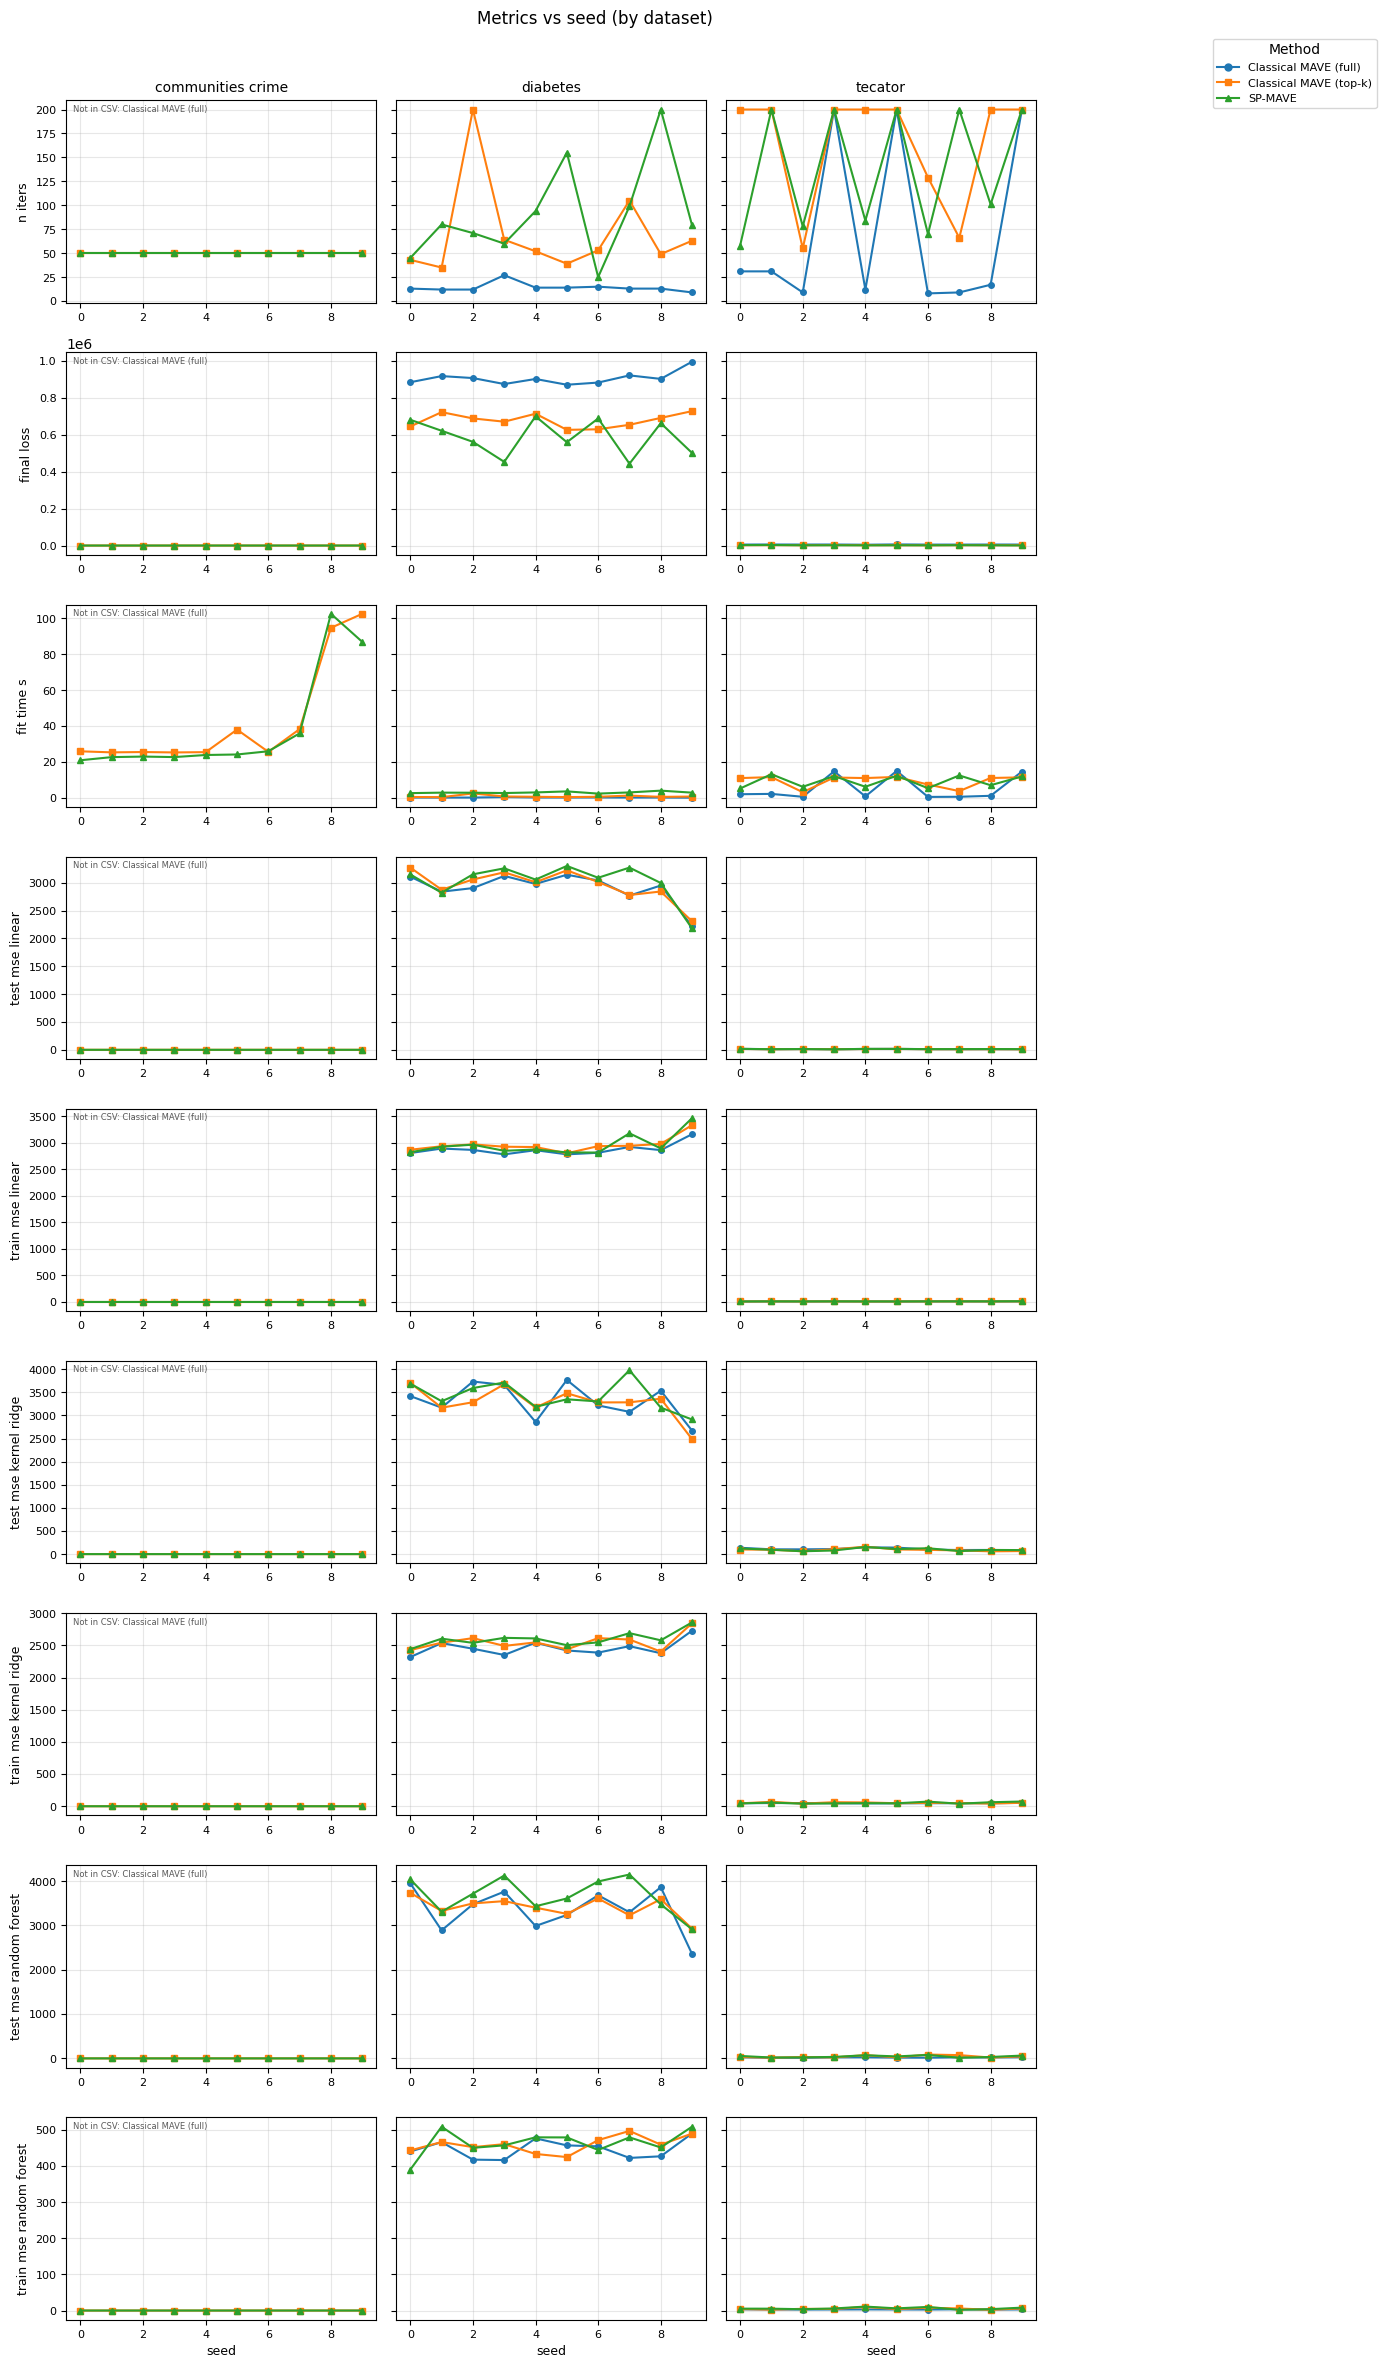

In [4]:
from __future__ import annotations

import csv
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Project root: cwd if it contains results/, else parent (when cwd is notebooks/)
ROOT = Path.cwd()
if not (ROOT / "results").is_dir():
    cand = ROOT.parent / "results"
    if cand.is_dir():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError(
            "Could not find results/ — open Jupyter with cwd = project root, "
            "or set ROOT = Path('/path/to/sp_mave') below."
        )

DATASETS = ["communities_crime", "diabetes", "tecator"]


def discover_metric_columns() -> list[str]:
    """All CSV columns except identifiers used for grouping / x-axis."""
    path = ROOT / "results" / DATASETS[0] / "tables" / "multi_seed_raw.csv"
    with path.open(newline="") as f:
        reader = csv.DictReader(f)
        if not reader.fieldnames:
            raise ValueError(f"No columns in {path}")
        skip = {"method", "seed"}
        return [c for c in reader.fieldnames if c not in skip]


METRICS = discover_metric_columns()

METHOD_STYLES: dict[str, tuple[str, str]] = {
    "Classical MAVE (full)": ("#1f77b4", "o-"),
    "Classical MAVE (top-k)": ("#ff7f0e", "s-"),
    "SP-MAVE": ("#2ca02c", "^-"),
}


def canonical_method_label(raw: str) -> str | None:
    if raw == "ClassicalMAVE":
        return "Classical MAVE (full)"
    if raw == "SPMAVE":
        return "SP-MAVE"
    if re.match(r"^ClassicalMAVE_k\d+$", raw):
        return "Classical MAVE (top-k)"
    return None


def load_series_by_method(dataset: str, metric: str) -> dict[str, list[tuple[int, float]]]:
    path = ROOT / "results" / dataset / "tables" / "multi_seed_raw.csv"
    if not path.is_file():
        raise FileNotFoundError(path)
    series: dict[str, list[tuple[int, float]]] = defaultdict(list)
    with path.open(newline="") as f:
        for row in csv.DictReader(f):
            label = canonical_method_label(row["method"])
            if label is None:
                continue
            seed = int(row["seed"])
            y = float(row[metric])
            series[label].append((seed, y))
    for label in series:
        series[label].sort(key=lambda t: t[0])
    return dict(series)


def _pretty_metric(name: str) -> str:
    return name.replace("_", " ")


def plot_metrics_by_seed() -> plt.Figure:
    n_m, n_d = len(METRICS), len(DATASETS)
    fig_w = max(4.0 * n_d, 10)
    fig_h = max(2.6 * n_m, 4)
    fig, axes = plt.subplots(n_m, n_d, figsize=(fig_w, fig_h), sharey="row", squeeze=False)

    for i, metric in enumerate(METRICS):
        axes[i, 0].set_ylabel(_pretty_metric(metric), fontsize=9)
        for j, ds in enumerate(DATASETS):
            ax = axes[i, j]
            by_method = load_series_by_method(ds, metric)
            present = set(by_method)
            for label, (color, fmt) in METHOD_STYLES.items():
                if label not in present:
                    continue
                xs, ys = zip(*by_method[label])
                ax.plot(xs, ys, fmt, color=color, markersize=4)
            if i == 0:
                ax.set_title(ds.replace("_", " "), fontsize=10)
            if i == n_m - 1:
                ax.set_xlabel("seed", fontsize=9)
            ax.tick_params(axis="both", labelsize=8)
            ax.grid(True, alpha=0.3)
            missing = set(METHOD_STYLES) - present
            if missing:
                ax.text(
                    0.02,
                    0.98,
                    "Not in CSV: " + ", ".join(sorted(missing)),
                    transform=ax.transAxes,
                    va="top",
                    fontsize=6,
                    color="0.35",
                )

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=color,
            marker=fmt[0],
            linestyle=fmt[1:] if len(fmt) > 1 else "-",
            markersize=5,
            label=label,
        )
        for label, (color, fmt) in METHOD_STYLES.items()
    ]
    fig.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        fontsize=8,
        title="Method",
    )
    fig.suptitle("Metrics vs seed (by dataset)", y=1.01, fontsize=12)
    fig.tight_layout(rect=(0, 0, 0.88, 1))
    return fig


fig = plot_metrics_by_seed()
plt.show()

## Optional: custom metric subset

After `METRICS = discover_metric_columns()`, you can narrow the list, e.g.  
`METRICS = ["test_mse_linear", "test_mse_random_forest", "final_loss"]`.

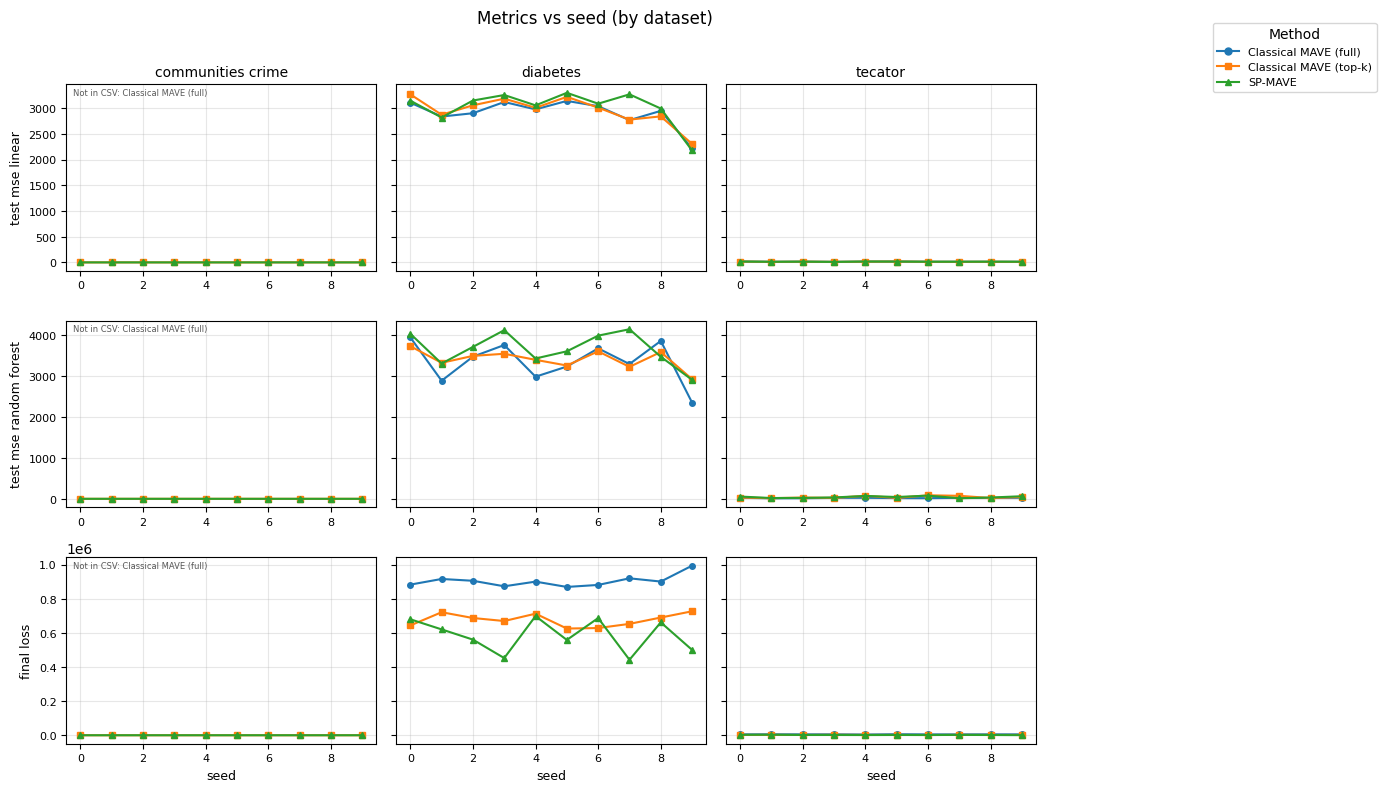

In [5]:
METRICS = ["test_mse_linear", "test_mse_random_forest", "final_loss"]
fig = plot_metrics_by_seed()
plt.show()